# 02 — Intervalos de confiança e teste de hipótese

> **stats-foundations · Fase 1** — quantificando a incerteza da taxa de conversão e decidindo testes A/B com método.

No [notebook 01](01-distribuicoes-marketing.ipynb) vimos que a taxa de conversão é a média de uma
**Bernoulli** — ou seja, uma *estimativa* com incerteza. Aqui respondemos as duas perguntas que
vêm logo em seguida, e que todo gestor de tráfego enfrenta:

1. **"Minha conversão é 12% — mas 12% com que margem?"** → *intervalo de confiança*.
2. **"A variação B converteu mais que a A — isso é real ou sorte?"** → *teste de hipótese*.

Estes são exatamente os cálculos que empacotei nas skills `ab-test-decisao` e `tamanho-amostra-teste`.
Aqui eu **abro a caixa-preta** e mostro a estatística por trás.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

RNG = np.random.default_rng(42)
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 11,
})
print("ok")

ok


## A. Intervalo de confiança para a taxa de conversão

### O que é (e o que NÃO é)

Um **intervalo de confiança de 95%** é uma faixa construída por um procedimento que, se repetido
muitas vezes, **captura a taxa verdadeira em 95% das vezes**. Interpretação correta: a confiança
está no *método*, não numa probabilidade sobre o número específico.

Na prática de tráfego, o IC é **mais útil que o p-valor sozinho** porque responde a pergunta de negócio:
*"entre quais valores a conversão real provavelmente está?"*. "12% [IC 9%–15%]" diz muito mais para
uma decisão de budget do que "p = 0,03".

Para proporção usamos o **intervalo de Wilson**, que é mais preciso que o ingênuo (Wald) quando a
amostra é pequena ou a taxa é baixa — caso comum em conversão.

In [2]:
# Helpers: IC de Wald (ingênuo) e Wilson (recomendado) para uma proporção
def ic_wald(conversoes, n, conf=0.95):
    p = conversoes / n
    z = stats.norm.ppf(1 - (1 - conf) / 2)
    se = np.sqrt(p * (1 - p) / n)
    return p - z * se, p + z * se

def ic_wilson(conversoes, n, conf=0.95):
    p = conversoes / n
    z = stats.norm.ppf(1 - (1 - conf) / 2)
    denom = 1 + z**2 / n
    centro = (p + z**2 / (2 * n)) / denom
    margem = (z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2))) / denom
    return centro - margem, centro + margem

# Uma campanha observada: 300 leads, 36 conversões
n, c = 300, 36
p_obs = c / n
lo_wald, hi_wald = ic_wald(c, n)
lo_wil, hi_wil = ic_wilson(c, n)

print(f"Taxa observada: {p_obs:.1%}  ({c}/{n} leads)")
print(f"IC 95% Wald  : [{lo_wald:.1%}, {hi_wald:.1%}]")
print(f"IC 95% Wilson: [{lo_wil:.1%}, {hi_wil:.1%}]  <- usar este")

Taxa observada: 12.0%  (36/300 leads)
IC 95% Wald  : [8.3%, 15.7%]
IC 95% Wilson: [8.8%, 16.2%]  <- usar este


### O IC encolhe conforme entram mais leads

A largura do intervalo cai com √n. É a tradução visual de "mais dados = mais confiança" — e é o que
justifica esperar a amostra mínima antes de decidir um teste.

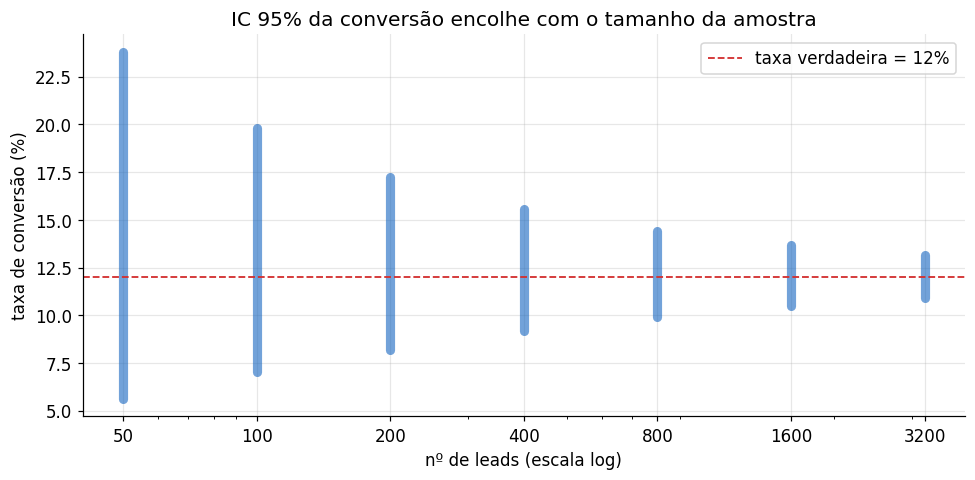

n=   50  ->  largura do IC = +/- 9.1 p.p.
n=  100  ->  largura do IC = +/- 6.4 p.p.
n=  200  ->  largura do IC = +/- 4.5 p.p.
n=  400  ->  largura do IC = +/- 3.2 p.p.
n=  800  ->  largura do IC = +/- 2.3 p.p.
n= 1600  ->  largura do IC = +/- 1.6 p.p.
n= 3200  ->  largura do IC = +/- 1.1 p.p.


In [3]:
p_verdadeiro = 0.12
ns = np.array([50, 100, 200, 400, 800, 1600, 3200])
larguras = []
fig, ax = plt.subplots(figsize=(9, 4.5))
for n_i in ns:
    c_i = int(round(n_i * p_verdadeiro))
    lo, hi = ic_wilson(c_i, n_i)
    larguras.append((hi - lo) * 100)
    ax.plot([n_i, n_i], [lo * 100, hi * 100], color="#1565c0", lw=6, alpha=0.6,
            solid_capstyle="round")
ax.axhline(p_verdadeiro * 100, color="#d32f2f", ls="--", lw=1.2,
           label=f"taxa verdadeira = {p_verdadeiro:.0%}")
ax.set_xscale("log")
ax.set_xticks(ns); ax.set_xticklabels(ns)
ax.set_title("IC 95% da conversão encolhe com o tamanho da amostra")
ax.set_xlabel("nº de leads (escala log)"); ax.set_ylabel("taxa de conversão (%)")
ax.legend()
fig.tight_layout(); plt.show()

for n_i, w in zip(ns, larguras):
    print(f"n={n_i:>5}  ->  largura do IC = +/- {w/2:.1f} p.p.")

### Provando a interpretação: cobertura de 95%

Se o IC de 95% está correto, ao repetir o experimento muitas vezes ~95% dos intervalos devem conter
a taxa verdadeira. Vamos simular e contar.

Cobertura observada em 5000 experimentos: 96.5%  (alvo: 95%)


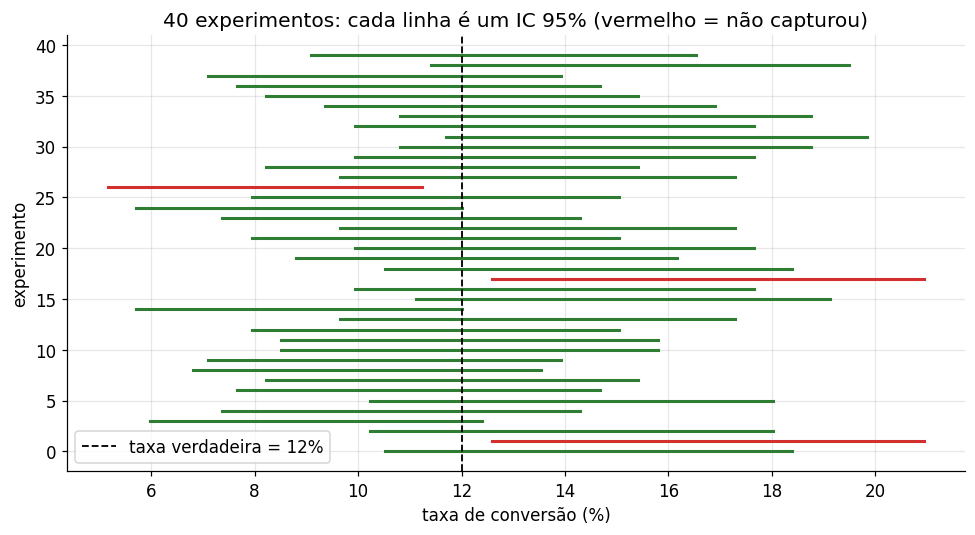

In [4]:
p_verdadeiro = 0.12
n_exp = 300          # leads por experimento
n_simulacoes = 5000

contem = 0
for _ in range(n_simulacoes):
    amostra = RNG.binomial(n_exp, p_verdadeiro)
    lo, hi = ic_wilson(amostra, n_exp)
    if lo <= p_verdadeiro <= hi:
        contem += 1
cobertura = contem / n_simulacoes
print(f"Cobertura observada em {n_simulacoes} experimentos: {cobertura:.1%}  (alvo: 95%)")

# Visualizar 40 experimentos: verde = capturou a taxa verdadeira, vermelho = errou
fig, ax = plt.subplots(figsize=(9, 5))
for i in range(40):
    amostra = RNG.binomial(n_exp, p_verdadeiro)
    lo, hi = ic_wilson(amostra, n_exp)
    capturou = lo <= p_verdadeiro <= hi
    ax.plot([lo * 100, hi * 100], [i, i],
            color="#2e7d32" if capturou else "#d32f2f", lw=2)
ax.axvline(p_verdadeiro * 100, color="black", ls="--", lw=1.2,
           label=f"taxa verdadeira = {p_verdadeiro:.0%}")
ax.set_title("40 experimentos: cada linha é um IC 95% (vermelho = não capturou)")
ax.set_xlabel("taxa de conversão (%)"); ax.set_ylabel("experimento")
ax.legend()
fig.tight_layout(); plt.show()

## B. Teste de hipótese — duas proporções (o A/B)

### A lógica

- **Hipótese nula (H₀):** as duas variações têm a mesma conversão (a diferença é zero).
- **Hipótese alternativa (H₁):** elas diferem.
- O **p-valor** responde: *"se H₀ fosse verdade, qual a chance de observar uma diferença tão grande
  quanto a que vi, só por acaso?"*. Se p < α (tipicamente 0,05), rejeitamos H₀ → a diferença é
  **estatisticamente significativa**.

Dois erros possíveis: **Tipo I** (α) = dizer que há efeito quando não há (falso positivo);
**Tipo II** (β) = não detectar um efeito que existe. Poder = 1 − β (assunto do notebook de amostra).

In [5]:
# A/B: controle vs teste
na, ca = 1000, 120   # variação A: 1000 leads, 120 conversões (12,0%)
nb, cb = 1000, 150   # variação B: 1000 leads, 150 conversões (15,0%)
pa, pb = ca/na, cb/nb

# Teste z de duas proporções (pooled), bicaudal
p_pool = (ca + cb) / (na + nb)
se = np.sqrt(p_pool * (1 - p_pool) * (1/na + 1/nb))
z = (pb - pa) / se
p_valor = 2 * (1 - stats.norm.cdf(abs(z)))

print(f"A: {pa:.1%}   B: {pb:.1%}   diferença: {(pb-pa)*100:+.1f} p.p.")
print(f"z = {z:.3f}   p-valor = {p_valor:.4f}")
print("=> significativo (p < 0,05)" if p_valor < 0.05 else "=> NÃO significativo")

A: 12.0%   B: 15.0%   diferença: +3.0 p.p.
z = 1.963   p-valor = 0.0496
=> significativo (p < 0,05)


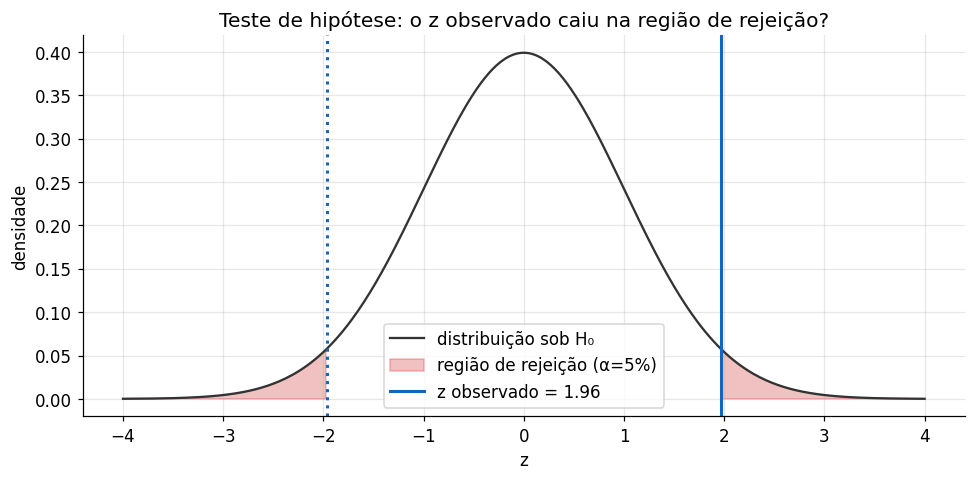

In [6]:
# Visualizar: sob H0, z ~ Normal(0,1). Onde cai o nosso z observado?
x = np.linspace(-4, 4, 400)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(x, stats.norm.pdf(x), color="#333", lw=1.5, label="distribuição sob H₀")
zc = stats.norm.ppf(0.975)
ax.fill_between(x, 0, stats.norm.pdf(x), where=np.abs(x) >= zc,
                color="#d32f2f", alpha=0.3, label="região de rejeição (α=5%)")
ax.axvline(z, color="#1565c0", lw=2, label=f"z observado = {z:.2f}")
ax.axvline(-z, color="#1565c0", lw=2, ls=":")
ax.set_title("Teste de hipótese: o z observado caiu na região de rejeição?")
ax.set_xlabel("z"); ax.set_ylabel("densidade"); ax.legend()
fig.tight_layout(); plt.show()

## C. A ponte IC ↔ teste, e a visão bayesiana

Duas leituras da mesma decisão:

- **Frequentista:** se o **IC 95% da diferença** entre B e A **não contém o zero**, a diferença é
  significativa a 5% — é a mesma conclusão do teste. O IC ainda dá o *bônus* de mostrar o **tamanho**
  do efeito, não só se ele existe.
- **Bayesiana:** modelamos cada taxa como uma distribuição **Beta** (a "crença" sobre o valor real
  dado os dados) e calculamos direto **P(B > A)** — a frase que um cliente entende: *"há 97% de chance
  de B ser melhor"*. É o que a skill `ab-test-decisao` também reporta.

Diferença B-A: 3.0%   IC 95%: [0.0%, 6.0%]
contém zero? -> NÃO (significativo)


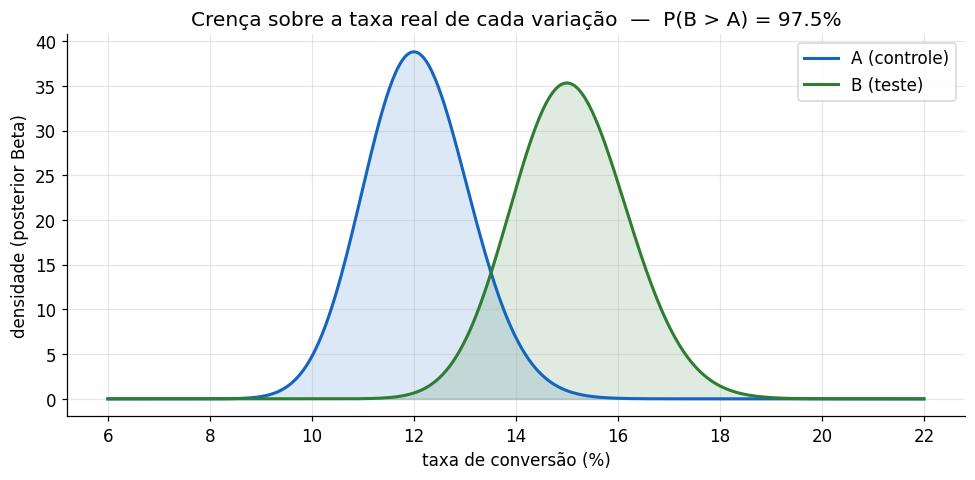

P(B melhor que A) = 97.5%


In [7]:
# IC 95% da DIFERENÇA (B - A), SE não-pooled
se_diff = np.sqrt(pa*(1-pa)/na + pb*(1-pb)/nb)
zc = stats.norm.ppf(0.975)
dif = pb - pa
lo_d, hi_d = dif - zc*se_diff, dif + zc*se_diff
print(f"Diferença B-A: {dif:.1%}   IC 95%: [{lo_d:.1%}, {hi_d:.1%}]")
print("contém zero? ->", "SIM (não significativo)" if lo_d <= 0 <= hi_d else "NÃO (significativo)")

# Posteriores bayesianas (prior uniforme Beta(1,1))
xs = np.linspace(0.06, 0.22, 500)
post_a = stats.beta(1 + ca, 1 + na - ca)
post_b = stats.beta(1 + cb, 1 + nb - cb)

draws = 200_000
prob_b = (post_b.rvs(draws, random_state=RNG) > post_a.rvs(draws, random_state=RNG)).mean()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(xs*100, post_a.pdf(xs), color="#1565c0", lw=2, label="A (controle)")
ax.fill_between(xs*100, 0, post_a.pdf(xs), color="#1565c0", alpha=0.15)
ax.plot(xs*100, post_b.pdf(xs), color="#2e7d32", lw=2, label="B (teste)")
ax.fill_between(xs*100, 0, post_b.pdf(xs), color="#2e7d32", alpha=0.15)
ax.set_title(f"Crença sobre a taxa real de cada variação  —  P(B > A) = {prob_b:.1%}")
ax.set_xlabel("taxa de conversão (%)"); ax.set_ylabel("densidade (posterior Beta)")
ax.legend()
fig.tight_layout(); plt.show()
print(f"P(B melhor que A) = {prob_b:.1%}")

## Resumo — o que isto vira na operação

| Conceito | Pergunta de negócio | Ferramenta |
|---|---|---|
| **Intervalo de confiança** | "minha conversão real está entre quais valores?" | IC de Wilson; encolhe com √n |
| **Teste de hipótese** | "a diferença A/B é real ou ruído?" | z de duas proporções; p < α |
| **IC da diferença** | "qual o tamanho do efeito, com margem?" | se não cruza zero → significativo |
| **P(B > A) bayesiana** | "qual a chance de B ser melhor?" (linguagem de cliente) | posteriores Beta |

**Regra prática:** nunca decidir um A/B só pela taxa "parecer" maior. Olhar **IC da diferença** (cruza
zero?) **e** o tamanho do efeito (vale a troca?). Foi isso que codifiquei na skill `ab-test-decisao`.

**Próximo (notebook 03):** poder estatístico e **tamanho mínimo de amostra** *antes* do teste, e
**correção para múltiplos testes** quando comparo várias métricas/variantes ao mesmo tempo.